#### DE1: LOADING AND PROFILING THE DATA

In [1]:

import pandas as pd
from pathlib import Path

file_path = Path("data/raw/online_retail_II.xlsx")


print("File Exists:",file_path.exists())
print("File Path:",file_path.resolve())

File Exists: True
File Path: D:\NU_2026\MATHS\giftlane\data\raw\online_retail_II.xlsx


In [2]:
#LOADING BOTH EXCEL FILES


df_2009 = pd.read_excel(file_path,sheet_name="Year 2009-2010")
df_2010 = pd.read_excel(file_path,sheet_name ="Year 2010-2011")

#combining both sheets into one dataframe
df = pd.concat([df_2009,df_2010],ignore_index =True)
print("2009-10 shape:",df_2009.shape)
print("2010-11 shape",df_2010.shape)
print("Combined shape:",df.shape)

2009-10 shape: (525461, 8)
2010-11 shape (541910, 8)
Combined shape: (1067371, 8)


In [3]:
#INSPECTING COLUMNS, TYPES AND MISSING VALUES
print("Column names:")
print(df.columns.tolist())

print("data types:")
print(df.dtypes)

profile = pd.DataFrame({
    "Data Type":df.dtypes.astype(str),
    "Missing Count": df.isna().sum(),
    "Missing percentage":(df.isna().mean()*100).round(2)
    
})

display(profile)

print("Duplicate rows:",df.duplicated().sum())
print("Earliest Invoices:",df["InvoiceDate"].min())
print("latest Invoices:",df["InvoiceDate"].max())

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
data types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object


,Data Type,Missing Count,Missing percentage
Invoice,object,0,0.00
StockCode,object,0,0.00
Description,object,4382,0.41
Quantity,int64,0,0.00
InvoiceDate,datetime64[ns],0,0.00
Price,float64,0,0.00
Customer ID,float64,243007,22.77
Country,object,0,0.00


Duplicate rows: 34335
Earliest Invoices: 2009-12-01 07:45:00
latest Invoices: 2011-12-09 12:50:00


### DE2:Cleaning the transactions

In [4]:
#creating a separate copy for cleaning
clean_df = df.copy()
cleaning_log =[]

print("Original Rows:",len(df))
print("working Rows:",len(clean_df))

Original Rows: 1067371
working Rows: 1067371


In [5]:
#cleaning each cell
clean_df['Invoice'] = clean_df["Invoice"].astype("string").str.strip()
clean_df["StockCode"] = clean_df["StockCode"].astype("string").str.strip()


def apply_cleaning_rule(data,rule_name,mask):
    rows_before = len(data)
    rows_removed= int(mask.sum())

    
    data = data.loc[~mask].copy()

    cleaning_log.append({
        "Cleaning Rule": rule_name,
        "Rows Before": rows_before,
        "Rows Removed": rows_removed,
        "Rows Remaining":len(data)
    })

    return data



#removable cancellations
clean_df = apply_cleaning_rule( clean_df, "Cancellation invoices",clean_df["Invoice"].str.startswith("C",na=False))
#removing negative quantities
clean_df = apply_cleaning_rule(clean_df,"Non-Positive Quantities",clean_df["Quantity"] <=0)
#Removing negative prices
clean_df = apply_cleaning_rule(clean_df,"Non-Positive prices",clean_df["Price"]<=0)
#removing issing customer IDS
clean_df = apply_cleaning_rule(clean_df,"Missing CUstomer ID",clean_df["Customer ID"].isna())


#removing known non-product codes
non_product_codes = {"POST","M","D","BANK CHARGES"}
clean_df = apply_cleaning_rule(clean_df,"Non-Product StockCodes",clean_df["StockCode"].str.upper().isin(non_product_codes))
#ensuring dates are valid
clean_df["InvoiceDate"] = pd.to_datetime(clean_df["InvoiceDate"],errors="coerce")
clean_df =apply_cleaning_rule( clean_df,"Invalid Invoice",clean_df["InvoiceDate"].isna())

#cleaning log into datatframe:
cleaning_log = pd.DataFrame(cleaning_log)
print("Cleaning Completed!")
print("Rows before cleaning:",f"{len(df):,}")
print("Rows after cleaning",f"{len(clean_df):,}")

Cleaning Completed!
Rows before cleaning: 1,067,371
Rows after cleaning 802,965


In [6]:
required_columns = ["Invoice","StockCode","Description","Quantity",
                    "InvoiceDate","Price","Customer ID","Country"]
missing_columns = set(required_columns) - set(clean_df.columns)
assert  not missing_columns, f"Missing Columns:{missing_columns}"

print("Column Validation Passed! ")

assert clean_df["Customer ID"].notna().all()
assert (clean_df["Quantity"]>0).all()
assert(clean_df["Price"]>0 ).all()
assert not clean_df["Invoice"].str.startswith("C",na=False).any()

print("Cleaning validation passed!")

Column Validation Passed! 
Cleaning validation passed!


### DE2 -validation_checks

In [7]:
checks ={
    "Missing customer ID": clean_df["Customer ID"].isna().sum(),
    "Non-Positive Quantities":(clean_df["Quantity"]<=0).sum(),
    "Non-Positive price":(clean_df["Price"]<=0).sum(),
    "Cancellation invoices":clean_df["Invoice"].str.startswith("C",na=False).sum(),
    "Missing dates": clean_df["InvoiceDate"].isna().sum(),
    "Duplicate rows":clean_df.duplicated().sum()
}

print("CLEANING VALIDATION")
for name,count in checks.items():
    print(f"{name}:{count:,}")


#required cleaning rules should now pass
assert checks["Missing customer ID"]==0
assert checks["Non-Positive Quantities"]==0
assert checks["Non-Positive price"]==0
assert checks["Cancellation invoices"]==0
assert checks["Missing dates"]==0


print(f"Cleaned rows:{len(clean_df):,}")
print("Unique Customers",clean_df["Customer ID"].nunique())
print("Unique Stock codes",clean_df["StockCode"].nunique())
print("Date range",clean_df["InvoiceDate"].min(),"to", clean_df["InvoiceDate"].max())


#displaying cleaaning log:
print("Cleaning log:")
display(cleaning_log)

CLEANING VALIDATION
Missing customer ID:0
Non-Positive Quantities:0
Non-Positive price:0
Cancellation invoices:0
Missing dates:0
Duplicate rows:26,060
Cleaned rows:802,965
Unique Customers 5862
Unique Stock codes 4627
Date range 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Cleaning log:


,Cleaning Rule,Rows Before,Rows Removed,Rows Remaining
0,Cancellation invoices,1067371,19494,1047877
1,Non-Positive Quantities,1047877,3457,1044420
2,Non-Positive prices,1044420,2750,1041670
3,Missing CUstomer ID,1041670,236121,805549
4,Non-Product StockCodes,805549,2584,802965
5,Invalid Invoice,802965,0,802965


### SAVING THE DE1 AND DE2 REPORTS

In [8]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

profile.to_csv(output_dir/"data_profile.csv")
cleaning_log.to_csv(output_dir/"cleaning_log.csv",index=False)
print("Saved data_profile.csv and cleaning_log.csv")

Saved data_profile.csv and cleaning_log.csv


### DE3 - SPLITTING DATA BY TIME

In [9]:
clean_df = clean_df.sort_values("InvoiceDate").copy()
latest_date = clean_df["InvoiceDate"].max()
cutoff_date = latest_date - pd.DateOffset(months=2)

train= clean_df.loc[clean_df["InvoiceDate"]<cutoff_date].copy()
test = clean_df.loc[clean_df["InvoiceDate"]>cutoff_date].copy()

print("latest Transaction:",latest_date)
print("Test cutoff:",cutoff_date)
print("Training Rows:",f"{len(train):,}")
print("Test Rows:",f"{len(test):,}")

print("Training date range:")
print(train["InvoiceDate"].min(),"to",train["InvoiceDate"].max())

print("Test Date range:")
print(test["InvoiceDate"].min(),"to",test["InvoiceDate"].max())

#verifying that there's no temporal overlap
assert train["InvoiceDate"].max() < cutoff_date
assert test["InvoiceDate"].min() >= cutoff_date
assert len(train)+len(test) == len(clean_df)

print("Time Split validated!")

latest Transaction: 2011-12-09 12:50:00
Test cutoff: 2011-10-09 12:50:00
Training Rows: 684,357
Test Rows: 118,608
Training date range:
2009-12-01 07:45:00 to 2011-10-09 12:49:00
Test Date range:
2011-10-09 12:59:00 to 2011-12-09 12:50:00
Time Split validated!


In [12]:
#Saving the training and test files
output_dir = Path("outputs")
output_dir.mkdir(parents=True,exist_ok=True)

train.to_parquet(output_dir/ "train.parquet",index=False)
test.to_parquet(output_dir/"test.parquet",index=False)

print("Saved train.parquet and test.parquet")

Saved train.parquet and test.parquet


In [13]:



#identifying products eligible for recommendation

product_customer_counts = (train.groupby("StockCode")["Customer ID"].nunique())

eligible_products = set(
    product_customer_counts[product_customer_counts >=10].index)

#Building customer purchase history from training only
train_history = (
    train.groupby(["Customer ID","StockCode"])["Quantity"].sum())

#testing purchases for customers known during training
known_customers = set(train["Customer ID"].unique())

test_candidates = test[
test["Customer ID"].isin(known_customers)
 & test["StockCode"].isin(eligible_products)
].copy()

#removing products already purchased by that customer
test_pairs = test_candidates[
[
    
    (customer,product) not in train_history.index
    for customer,product in zip(
        test_candidates["Customer ID"],test_candidates["StockCode"]
    )
]
].copy()

#unique customer-product pairs form the ground truth
test_truth =(
    test_pairs.groupby("Customer ID")["StockCode"].apply(set)
)

#only customers with atleast one eligible held-out purchase
test_truth = test_truth[test_truth.map(len)>0]

print("ELigible products:",f"{len(eligible_products):,}")
print("Test customers with held out purchases:",f"{len(test_truth):,}")
print("Held-out Customer product pairs:",f"{sum(map(len,test_truth)):,}")

ELigible products: 3,690
Test customers with held out purchases: 1,913
Held-out Customer product pairs: 44,729


### DE4: BUILDING THE SPARSE CUSTOMER * PRODUCT MATRIX 

In [ ]:
from scipy.sparse import csr_matrix,save_npz
import numpy as np

purchases =(
    train.groupby(["Customer ID","StockCode"])["Quantity"].sum().reset_index()
)

#applying product filter using training data only
puchases = purchases[purchases["StockCode"].isin(eligible_products)].copy()

#compressing large quantities using log transformations
purchases["value"] = np.log1p(purchases["Quantity"])

#Building stable index maps
customers = sorted(purchases["Customer ID"].unique())
products = sorted(purchases["StockCode"].unique())

customer_to_idx = {
    customer: i for i, customer in enumerate(customers)
}
products_to_idx ={
    product: i for i, product in enumerate(products)
}

#constructing sparse matrix
rows = purchases["Customer ID"].map(customer_to_idx).to_numpy()
cols = purchases["StockCode"].map(products_to_idx).to_numpy()
values = purchases["value"].to_numpy(dtype=np.float64)

A= csr_matrix(
    (values,(rows,cols)),
    shape= (len(customers),len(products))
)



### DE5: REPORTING MATRIX SIZE, SPARSITY AND MEMORY

In [ ]:
#matrix report
total_cells = A.shape[0]*A.shape[1]
dense_mb = total_cells * 8 / (1024 ** 2)
sparse_mb = (A.data.nbytes + A.indices.nbytes + A.indptr.nbytes)/(1024 ** 2)

print("matrix Shape:",A.shape)
print("Non-Zero entries:",f"{A.nnz:,}")
print("Sparsity:",f"{100 * (1-A.nnz/total_cells):.2f}%")
print("dense Memory:",f"{dense_mb:.2f}MB")
print("Sparse Memory",f"{sparse_mb:.2f}MB")

#Save Matrix
save_npz("Customer_product_matrix.npz",A)


matrix Shape: (5484, 4537)
Non-Zero entries: 417,809
Sparsity: 98.32%
dense Memory: 189.83MB
Sparse Memory 4.80MB


In [16]:
#saving index maps for reproducibility
import json
with open("customer_index.json","w") as f:
    json.dump([str(c) for c in customers],f)

with open("product_index.json","w") as f:
    json.dump(products,f)

print("Sparse Matrix and index maps are saved!!!")

Sparse Matrix and index maps are saved!!!


### ML1 — Method selection

**Primary method: Truncated Singular Value Decomposition (Truncated SVD).**

The customer–product matrix is sparse because most customers purchase only a small subset of the catalogue. Truncated SVD can operate directly on this sparse matrix without centering it, making it a suitable first choice for a product recommendation system.

The model compresses customer purchasing patterns into latent factors. Products with similar factor vectors can then be identified using cosine similarity.

PCA will be fitted on the same training matrix, using the same component count, as a comparison. The final choice will consider recommendation Hit Rate@10, reconstruction quality, fitting time, and factor storage size.

### ML2: Comparing Component counts we'll test k= 10,20,50,100,200

  k  fit_seconds  capured_energy  relative_reconstruction_error  factor_size_MB
 10     0.087031        0.231542                       0.876617        0.764542
 20     0.139379        0.283558                       0.846429        1.529083
 50     0.297927        0.375115                       0.790496        3.822708
100     0.632456        0.468724                       0.728887        7.645416
200     1.567474        0.589183                       0.640950       15.290833


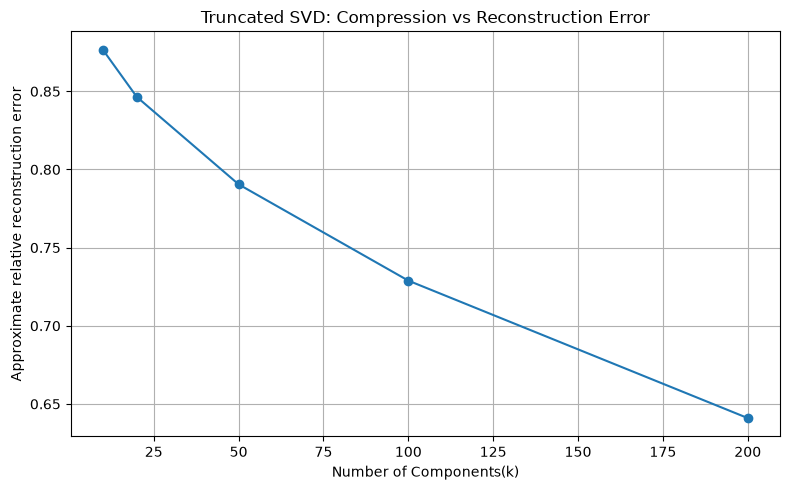

In [18]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

K_VALUES = [10,20,50,100,200]
RANDOM_STATE =42

#validating that each requested k is possible
max_k = min(A.shape)-1
valid_k = [k for k in K_VALUES if k<=max_k]

if len(valid_k) != len(K_VALUES):
    print("Some k values are invalid for this matrix.")
    print("Maximum allowed k for this experiment:",max_k)


svd_models={}
svd_results=[]

matrix_norm_sq = float(A.multiply(A).sum())

for k in valid_k:
    start = time.perf_counter()

    model = TruncatedSVD(
        n_components=k,n_iter=5,random_state=RANDOM_STATE)
    model.fit(A)

    fit_seconds = time.perf_counter() - start
    svd_models[k] = model
    #Approximate relative reconstruction error.
    captured_sq = float(np.sum(model.singular_values_ ** 2))
    relative_error = np.sqrt(
        max(0.0,1.0 - captured_sq / matrix_norm_sq)
    )
    factor_bytes =(
        model.transform(A).nbytes
        + model.components_.nbytes
    )

    svd_results.append({
        "k":k,
        "fit_seconds":fit_seconds,
        "capured_energy":captured_sq /matrix_norm_sq,
        "relative_reconstruction_error": relative_error,
        "factor_size_MB": factor_bytes / (1024 ** 2)
    })

svd_results = pd.DataFrame(svd_results)
print(svd_results.to_string(index=False))

plt.figure(figsize=(8,5))
plt.plot(
    svd_results["k"],
    svd_results["relative_reconstruction_error"],
    marker ='o'
)

plt.xlabel("Number of Components(k)")
plt.ylabel("Approximate relative reconstruction error")
plt.title("Truncated SVD: Compression vs Reconstruction Error" )
plt.grid(True)
plt.tight_layout()
plt.savefig("svd_reconstruction_curve.png",dpi=150)
plt.show()


In [19]:
#defining customer and product index mappings
customers = sorted(purchases["Customer ID"].unique())
products = sorted(purchases["StockCode"].unique())

customer_to_idx ={
    customer:i
    for i ,customer in enumerate(customers)
}
product_to_idx = {
    product:i
    for i,product in enumerate(products)
}

print("Customer mapping:",len(customer_to_idx))
print("Product mappings:",len(product_to_idx))

Customer mapping: 5484
Product mappings: 4537


### ML3 and ML4: Building recommendations and Testing 


In [20]:
from sklearn.preprocessing import normalize
from collections import defaultdict

k = 50
svd = svd_models[k]

product_vectors = normalize(svd.components_.T)
similarity = product_vectors @ product_vectors.T

#removing each product's self-similarity
np.fill_diagonal(similarity,-np.inf)

#Top-10 similar products for each product
top_similar_idx = np.argsort(-similarity,axis=1)[:,:10]

#Mapping matrix positions back to stock codes
product_codes = np.array(products)

def similar_products(stock_code,n=10):
    if stock_code not in product_to_idx:
        return[]
    j = product_to_idx[stock_code]
    indices = top_similar_idx[j,:n]
    return product_codes[indices].tolist()


#Training purchase history:product codes per customer
customer_bought = (
    purchases.groupby("Customer ID")["StockCode"]
    .apply(set).to_dict()
)

#Training best-seller baseline
top_sellers = (
    purchases.groupby("StockCode")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .index.tolist()
)

#ranking each product by total cosine similarity to the products purchased by the customer
def recommend_for_customer(customer_id,n=10):
    bought = customer_bought.get(customer_id,set())
    seed_indices =[
        product_to_idx[p]
        for p in bought 
        if p in product_to_idx
    ]
    if not seed_indices:
        return []
    scores = similarity[:,seed_indices].sum(axis=1)
    scores = np.asarray(scores).ravel()

    #never recommending products already bought in training
    for p in bought:
        if p in product_to_idx:
            scores[product_to_idx[p]] = -np.inf
    #Highest scores first
    order = np.argsort(-scores)
    return [
        product_codes[j]
        for j in order
        if np.isfinite(scores[j])
    ][:n]

#Hit rate @10 evaluation
eligible_test_customers = [
    customer_id for customer_id,heldout in test_truth.items()
    if customer_id in customer_bought and len(heldout)>0
]

#rebuilding baseline ranking from training only
top_sellers=[
    p for p in top_sellers
    if p in product_to_idx
]

def baseline_for_customer(customer_id,n=10):
    bought = customer_bought.get(customer_id,set())
    return [p for p in top_sellers if p not in bought][:n]

def hit_rate_at_10(recommendation_function):
    hits = 0
    for customer_id in eligible_test_customers:
        recs = set(recommendation_function(customer_id,10))
        actual = test_truth[customer_id]
        if recs.intersection(actual):
            hits += 1
    return hits / len(eligible_test_customers) if eligible_test_customers else 0.0

start = time.perf_counter()
model_hit_rate = hit_rate_at_10(recommend_for_customer)
scoring_seconds = time.perf_counter()- start

baseline_hit_rate = hit_rate_at_10(baseline_for_customer)
print(f"Evaluation Customers:{len(eligible_test_customers):,}")
print(f"Model Hit Rate@10:{model_hit_rate:.4%}")
print(f"Baseline Hit Rate@10:{baseline_hit_rate:.4%}")
print(f"Scoring all evaluation customers:{scoring_seconds:.2f}sec")
            
    


Evaluation Customers:1,913
Model Hit Rate@10:20.3346%
Baseline Hit Rate@10:17.4072%
Scoring all evaluation customers:28.97sec


### ML5: PCA vs SVD

In [30]:
import sklearn
from sklearn.decomposition import PCA
print("SK-Learn Version",sklearn.__version__)
pca_results = {}

try:
    start = time.perf_counter()
    pca = PCA(
        n_components=k,
        svd_solver ='arpack',
        random_state= RANDOM_STATE
    )
    pca.fit(A)

    pca_fit_seconds = time.perf_counter() - start
    pca_results["model"] = pca
    pca_results["fit_seconds"] = pca_fit_seconds
    pca_results["explained_variance"] = float(
        pca.explained_variance_ratio_.sum()
    )
    pca_factor_bytes =(
        pca.transform(A).nbytes +pca.components_.nbytes
    )
    print("PCA fit time:",round(pca_fit_seconds,2),"seconds")
    print(f"PCA explained variance:{pca_results["explained_variance"]:.4%}""\n"
         f"PCA factor storage:{pca_factor_bytes / (1024 ** 2):.2f}MB")
    
except(ValueError, TypeError,MemoryError) as e:
    print("PCA comparison could not complete:",repr(e))
    print("check your sklearn version and avalaible RAM.")
    
   
    

SK-Learn Version 1.9.1
PCA fit time: 0.31 seconds
PCA explained variance:34.8584%
PCA factor storage:3.82MB


### ML-6: Creating the customer map and segments

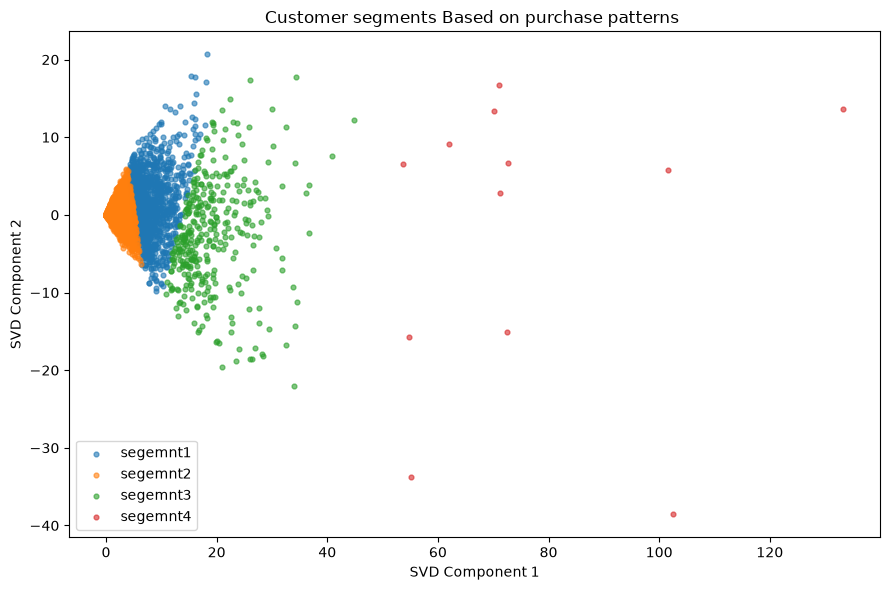

In [32]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

#2d customer representation
svd_2d = TruncatedSVD(
    n_components = 2,
    random_state = RANDOM_STATE
)
customer_coordinates = svd_2d.fit_transform(A)

#clustering customers into 4 segemnts
kmeans = KMeans(
    n_clusters = 4,
    random_state = RANDOM_STATE,
    n_init=10
)
segment_labels = kmeans.fit_predict(customer_coordinates)

#anonymous plotting
plt.figure(figsize=(9,6))

for segment in sorted(set(segment_labels)):
    mask = segment_labels == segment
    plt.scatter(
        customer_coordinates[mask,0],
        customer_coordinates[mask,1],
        label = f"segemnt{segment+1}",
        alpha =0.6,
        s=12
    )
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("Customer segments Based on purchase patterns ")
plt.legend()
plt.tight_layout()
plt.savefig("customer_segments.png",dpi=180)
plt.show()

In [33]:
#creating internal customer-segment mapping
customer_segments = pd.DataFrame({
    "Customer ID": customers,
    "segment":segment_labels
})

#segment descriptions from training data
train_with_segments = train.merge(
    customer_segments,
    on="Customer ID",
    how = "inner"
)

for segment in sorted(set(segment_labels)):
    group = train_with_segments[
    train_with_segments["segment"] == segment
    ]
    top_products =(
        group.groupby("StockCode")["Quantity"]
        .sum()
        .sort_values(ascending=False)
        .head(5)
        .index.tolist()
    )
    top_countries = group["Country"].value_counts().head(3)
    print("Segment:",segment+1)
    print("Customers:",group["Customer ID"].nunique())
    print("Top Products:",top_products)
    print("Top Countries:",top_countries.to_dict())

Segment: 1
Customers: 1114
Top Products: ['84077', '85123A', '85099B', '84879', '22197']
Top Countries: {'United Kingdom': 237444, 'Germany': 3026, 'France': 1865}
Segment: 2
Customers: 4005
Top Products: ['23166', '37410', '16014', '84077', '21982']
Top Countries: {'United Kingdom': 158293, 'Germany': 2580, 'France': 2032}
Segment: 3
Customers: 353
Top Products: ['21212', '85099B', '84077', '17003', '84879']
Top Countries: {'United Kingdom': 191358, 'Germany': 8229, 'France': 7088}
Segment: 4
Customers: 12
Top Products: ['21212', '85099B', '85123A', '22630', '22629']
Top Countries: {'United Kingdom': 30182, 'EIRE': 13143, 'Netherlands': 3328}


In [24]:
#Finalizing DE deliverables
from pathlib import Path
import json

output_dir = Path("outputs") 
output_dir.mkdir(exist_ok = True)

#Data profile
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count":df.isna().sum(),
    "missing_percent":df.isna().mean()*100
})

profile.to_csv(output_dir/"data_profile.csv")

#cleaning log
cleaning_log.to_csv(
    output_dir/"cleaning_log.csv",index=False
)

#Split summaries
pd.DataFrame([
    {
        "split":"train",
        "rows": len(train),
        "customers":train["Customer ID"].nunique(),
        "products":train["StockCode"].nunique()
    },
    {
        "split":"test",
        "rows":len(test),
        "customers":test["Customer ID"].nunique(),
        "products":test["StockCode"].nunique()
    }]).to_csv(output_dir/"split_report.csv",index=False)

#Matrix Report
pd.DataFrame([{
    "customers":A.shape[0],
    "products":A.shape[1],
    "nonzeros":A.nnz,
    "sparsity_percent":100*(1-A.nnz /(A.shape[0] * A.shape[1])),
    "dense_MB": dense_mb,
    "sparse_MB": sparse_mb
    
}]).to_csv(output_dir/"matrix_report.csv",index=False)
print("DE Reports Saved in outputs/")

DE Reports Saved in outputs/


In [34]:
from pathlib import Path

output_dir = Path("outputs")

for name in [
    "data_profile.csv",
    "cleaning_log.csv",
    "split_report.csv",
    "matrix_report.csv",
]:
    path = output_dir / name
    print(
        name,
        "| exists:", path.exists(),
        "| bytes:", path.stat().st_size if path.exists() else "N/A"
    )

data_profile.csv | exists: True | bytes: 274
cleaning_log.csv | exists: True | bytes: 307
split_report.csv | exists: True | bytes: 78
matrix_report.csv | exists: True | bytes: 136


In [35]:
# All recommendation products must be in the training matrix.
assert len(products) == A.shape[1]
assert set(products) == set(product_to_idx)

if isinstance(test_truth, pd.Series):
    truth_values = test_truth.tolist()
elif isinstance(test_truth, dict):
    truth_values = list(test_truth.values())
else:
    raise TypeError(f"Unexpected test_truth type: {type(test_truth)}")

truth_products = set()
for item in truth_values:
    if isinstance(item, (set, list, tuple)):
        truth_products.update(item)
    elif pd.notna(item):
        truth_products.add(item)

assert truth_products.issubset(set(products)), (
f"{len(truth_products - set(products))} held-out products "
"are missing from the training matrix."
)

print("Matrix/product mappings and held-out truth checks passed.")
print("Eligible evaluation customers:", len(eligible_test_customers))

Matrix/product mappings and held-out truth checks passed.
Eligible evaluation customers: 1913


In [41]:
#saving the svd comparison 
from pathlib import Path
import pandas as pd

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Get the SVD results at k=50
svd_row = svd_results.loc[svd_results["k"] == 50].iloc[0]

# Build a comparison using the actual recorded outputs
comparison = pd.DataFrame([
    {
        "method": "Truncated SVD",
        "components": 50,
        "fit_seconds": float(svd_row["fit_seconds"]),
        "quality_metric": "Approximate relative reconstruction error",
        "quality_value": float(svd_row["relative_reconstruction_error"]),
        "factor_storage_MB": float(svd_row["factor_size_MB"]),
    },
    {
        "method": "PCA",
        "components": 50,
        "fit_seconds": float(pca_results["fit_seconds"]),
        "quality_metric": "Cumulative explained variance",
        "quality_value": float(pca_results["explained_variance"]),
        "factor_storage_MB": float(pca_factor_bytes / (1024 ** 2)),
    },
])

comparison.to_csv(
    output_dir / "pca_svd_comparison.csv",
    index=False
)

print(comparison.to_string(index=False))
print("\nSaved:", (output_dir / "pca_svd_comparison.csv").resolve())

       method  components  fit_seconds                            quality_metric  quality_value  factor_storage_MB
Truncated SVD          50     0.297927 Approximate relative reconstruction error       0.790496           3.822708
          PCA          50     0.312586             Cumulative explained variance       0.348584           3.822708

Saved: D:\NU_2026\MATHS\giftlane\outputs\pca_svd_comparison.csv


In [42]:
import pandas as pd
import numpy as np
import scipy
import sklearn
import matplotlib
import openpyxl
import pyarrow

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scipy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)
print("openpyxl:", openpyxl.__version__)
print("pyarrow:", pyarrow.__version__)

pandas: 2.2.3
numpy: 2.5.4
scipy: 1.18.1
scikit-learn: 1.9.1
matplotlib: 3.11.2
openpyxl: 3.1.5
pyarrow: 20.0.0
